# ToysAD-8K DS2 Confirmation and Multi-view Evaluation

**Notebook file:** `08c-toysad8k-ds2-confirmation-and-multiview.ipynb`

This evaluator-only notebook opens the protected DS2 labels after the LocateAnything, SAM 2.1, and DINOv2-small prediction files are complete and hash locked. It evaluates the fixed DS2 operational route v2, including proposal generation failures and masks that are too small for DINO scoring. It measures proposal and mask quality, compares B0 with P1 across supplied, assisted, and automatic routes, and reports fixed camera-spread view subsets and fusion rules.

It does not load or run a model. It does not tune from calibration or internal-lock data.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08C DS2 confirmation and multiview`  
Clean notebook SHA-256: `0e00b4a173effa185070300b4ed356013a6ba1ec10482f7734d95e7e2a8864d4`  
Downloaded saved-output SHA-256: `625e9f7feadd7e5628df63fdfb096be0d00603831702002458df2416383c7f17`


## Predeclared evaluation

- View counts: 1, 2, 3, 5, 10, and 20.
- Application condition: three evenly spaced views.
- Fusion reports: mean normalized rank and visibility-weighted normalized rank.
- One-anomaly metrics: Top-1, MRR, and scene AP.
- Two-anomaly metrics: AP, Recall@2, and exact-set recovery.
- Uncertainty: paired confidence intervals clustered by base asset.
- Failure analysis: category, anomaly family, object count, anomaly count, rank disagreement, and low-margin scenes.

DS2 is a confirmation cohort. Both fusion reports are retained, but the predeclared mean-rank rule remains the application setting. No accuracy cutoff or DS2-based model tuning is applied.

In [1]:
from __future__ import annotations

from hashlib import sha256
import json
import os
from pathlib import Path
import shutil
import subprocess
import sys
import zipfile

sys.dont_write_bytecode = True

from IPython.display import Image as NotebookImage, display

NOTEBOOK_NAME = "08c-toysad8k-ds2-confirmation-and-multiview.ipynb"
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/input").is_dir() else "local"
OUTPUT_ROOT = Path(os.getenv(
    "VPI_OUTPUT_ROOT",
    "/kaggle/temp/toysad8k_ds2_confirmation_evaluation" if EXECUTION_ENVIRONMENT == "kaggle" else ".local/runs/toysad8k-ds2-confirmation-evaluation",
)).expanduser().resolve()

In [2]:
def kaggle_dataset_roots() -> list[Path]:
    input_root = Path("/kaggle/input")
    if not input_root.is_dir():
        return []
    candidates: list[Path] = []
    for pattern in (
        "*",
        "datasets/*/*",
        "datasets/*/*/versions/*",
        "notebooks/*/*",
        "notebooks/*/*/versions/*",
    ):
        candidates.extend(path for path in input_root.glob(pattern) if path.is_dir())
    return sorted(set(candidates), key=lambda path: path.as_posix())


def find_code_root() -> Path:
    configured = os.getenv("VPI_CODE_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    candidates.extend((Path.cwd(), *Path.cwd().parents))
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for mounted in kaggle_dataset_roots():
            candidates.extend((mounted, mounted / "code"))
    for candidate in candidates:
        if (candidate / "src/visual_peer_inspector/data/cohort_contract.py").is_file():
            return candidate.resolve()
    mounted_names = sorted(path.name for path in input_root.iterdir()) if input_root.is_dir() else []
    raise FileNotFoundError(
        f"Could not locate the Visual Peer Inspector code snapshot. Mounted inputs: {mounted_names}"
    )


def find_package(package_kind: str, variable: str) -> Path:
    configured = os.getenv(variable)
    candidates = [Path(configured).expanduser()] if configured else []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for mounted in kaggle_dataset_roots():
            candidates.append(mounted)
            candidates.extend(
                child for child in sorted(mounted.iterdir()) if child.is_dir()
            )
    for candidate in candidates:
        record_path = candidate / "package_record.json"
        if not record_path.is_file():
            continue
        try:
            record = json.loads(record_path.read_text(encoding="utf-8"))
        except Exception:
            continue
        is_rgb_package = (
            package_kind == "toysad8k-model-input"
            and record.get("cohort_id") == "toysad8k-development-confirm-300-v1"
            and (candidate / "neutral_corpus_manifest.jsonl").is_file()
            and (candidate / "media").is_dir()
        )
        if record.get("package_kind") == package_kind or is_rgb_package:
            return candidate.resolve()
    raise FileNotFoundError(f"Could not locate package kind: {package_kind}")


def find_named_input_file(name: str, variable: str) -> Path:
    configured = os.getenv(variable)
    if configured:
        path = Path(configured).expanduser()
        if path.is_file():
            return path.resolve()
    patterns = (
        name,
        f"*/{name}",
        f"*/*/{name}",
        f"*/*/*/{name}",
        f"*/*/*/*/{name}",
    )
    matches = []
    for mounted in kaggle_dataset_roots():
        for pattern in patterns:
            matches.extend(path for path in mounted.glob(pattern) if path.is_file())
    unique = sorted(set(matches), key=lambda path: path.as_posix())
    if not unique:
        raise FileNotFoundError(f"Could not find mounted input file: {name}")
    digests = {sha256(path.read_bytes()).hexdigest() for path in unique}
    if len(digests) != 1:
        raise ValueError(f"Mounted copies of {name} do not match")
    preferred = sorted(
        unique,
        key=lambda path: ("downstream" not in path.parts, path.as_posix()),
    )
    return preferred[0].resolve()


def read_secret(name: str) -> str | None:
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.getenv(name)


def code_environment() -> dict[str, str]:
    environment = os.environ.copy()
    source_root = str(CODE_ROOT / "src")
    previous = environment.get("PYTHONPATH")
    environment["PYTHONPATH"] = source_root if not previous else source_root + os.pathsep + previous
    return environment


def run_clearml_finalizer(safe_root: Path, stage: str, task_name: str, tags: list[str], receipt: Path) -> dict:
    mode = "online" if EXECUTION_ENVIRONMENT == "kaggle" else "disabled"
    environment = code_environment()
    if mode == "online":
        access = read_secret("CLEARML_API_ACCESS_KEY")
        secret = read_secret("CLEARML_API_SECRET_KEY")
        if not access or not secret:
            mode = "disabled"
        else:
            environment.update({
                "CLEARML_API_ACCESS_KEY": access,
                "CLEARML_API_SECRET_KEY": secret,
                "CLEARML_API_HOST": "https://api.clear.ml",
                "CLEARML_WEB_HOST": "https://app.clear.ml",
                "CLEARML_FILES_HOST": "https://files.clear.ml",
            })
    command = [
        sys.executable,
        str(CODE_ROOT / "scripts/finalize_ds2_clearml.py"),
        "--safe-root", str(safe_root),
        "--receipt", str(receipt),
        "--stage", stage,
        "--task-name", task_name,
        "--mode", mode,
    ]
    for tag in tags:
        command.extend(("--tag", tag))
    try:
        subprocess.run(command, env=environment, check=True, timeout=240)
    except Exception as error:
        receipt.parent.mkdir(parents=True, exist_ok=True)
        receipt.write_text(json.dumps({
            "schema_version": 1,
            "status": "failed",
            "error_type": type(error).__name__,
            "task_id": None,
        }, indent=2) + "\\n", encoding="utf-8")
    return json.loads(receipt.read_text(encoding="utf-8"))

## Locate the frozen predictions and protected evaluator inputs

In [3]:
CODE_ROOT = find_code_root()
sys.path.insert(0, str(CODE_ROOT / "src"))
RGB_ROOT = find_package("toysad8k-model-input", "VPI_RGB_ROOT")
GEOMETRY_ROOT = find_package("ds2-oracle-geometry", "VPI_GEOMETRY_ROOT")
ATTRIBUTES_ROOT = find_package("ds2-evaluator-attributes", "VPI_ATTRIBUTES_ROOT")


def verified_extract(archive_path: Path, destination: Path) -> None:
    # Validate archive integrity and member paths before evaluator inputs are opened.
    with zipfile.ZipFile(archive_path) as archive:
        if archive.testzip() is not None:
            raise ValueError(f"Archive integrity failed: {archive_path.name}")
        for name in archive.namelist():
            member = Path(name)
            if member.is_absolute() or ".." in member.parts:
                raise ValueError(f"Unsafe archive member: {name}")
        archive.extractall(destination)


def verified_downstream_archive(archive_name: str) -> Path:
    stage_name = archive_name.removesuffix("-downstream-input.zip")
    archive_path = find_named_input_file(archive_name, "VPI_UNUSED_ARCHIVE")
    verification_path = find_named_input_file(
        f"{stage_name}-verification.json",
        "VPI_UNUSED_VERIFICATION",
    )
    verification = json.loads(verification_path.read_text(encoding="utf-8"))
    matches = [row for row in verification["archives"] if row["path"] == archive_name]
    if len(matches) != 1:
        raise ValueError(f"No unique verification record for {archive_name}")
    actual_sha256 = sha256(archive_path.read_bytes()).hexdigest()
    if actual_sha256 != matches[0]["sha256"]:
        raise ValueError(f"Archive SHA-256 differs from the producer record: {archive_name}")
    checksums_path = verification_path.parent / "SHA256SUMS"
    if not checksums_path.is_file():
        raise FileNotFoundError(f"Checksum manifest is missing for {archive_name}")
    checksums = {
        line.split(maxsplit=1)[1].strip(): line.split(maxsplit=1)[0]
        for line in checksums_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    }
    if checksums.get(archive_name) != actual_sha256:
        raise ValueError(f"Archive SHA-256 differs from SHA256SUMS: {archive_name}")
    return archive_path


configured_inference = os.getenv("VPI_INFERENCE_ROOT")
if configured_inference:
    INFERENCE_ROOT = Path(configured_inference).expanduser().resolve()
else:
    INFERENCE_ROOT = Path("/kaggle/temp/ds2_evaluator_inference_inputs").resolve()
    marker = INFERENCE_ROOT / "representation/model-input/package_record.json"
    if not marker.is_file():
        archive_specs = [
            ("ds2-reference-sam21-downstream-input.zip", INFERENCE_ROOT / "sam21/reference-box"),
            ("ds2-automatic-sam21-downstream-input.zip", INFERENCE_ROOT / "sam21/automatic-box"),
            ("ds2-dinov2-p1-downstream-input.zip", INFERENCE_ROOT / "representation"),
        ]
        for archive_name, destination in archive_specs:
            destination.mkdir(parents=True, exist_ok=True)
            verified_extract(verified_downstream_archive(archive_name), destination)

SCORE_ROOT = INFERENCE_ROOT / "representation/model-input"
REFERENCE_SAM_RESULTS = INFERENCE_ROOT / "sam21/reference-box/private/sam_results.jsonl"
AUTOMATIC_SAM_RESULTS = INFERENCE_ROOT / "sam21/automatic-box/private/sam_results.jsonl"
for required in (SCORE_ROOT / "package_record.json", REFERENCE_SAM_RESULTS, AUTOMATIC_SAM_RESULTS):
    if not required.is_file():
        raise FileNotFoundError(f"Frozen DS2 evaluator input is missing: {required.name}")

score_record = json.loads((SCORE_ROOT / "package_record.json").read_text(encoding="utf-8"))
display({
    "score package status": score_record["all_checks_passed"],
    "score rows": score_record["score_row_count"],
    "model": score_record["model_key"],
    "methods": score_record["methods"],
    "evaluator opened during inference": score_record["evaluator_opened"],
    "reference SAM results": REFERENCE_SAM_RESULTS.name,
    "automatic SAM results": AUTOMATIC_SAM_RESULTS.name,
})

{'score package status': True,
 'score rows': 138760,
 'model': 'dinov2_small',
 'methods': ['B0', 'P1'],
 'evaluator opened during inference': False,
 'reference SAM results': 'sam_results.jsonl',
 'automatic SAM results': 'sam_results.jsonl'}

## Run the protected confirmation and multi-view analysis

In [4]:
command = [
    sys.executable,
    str(CODE_ROOT / "scripts/run_ds2_confirmation_evaluation.py"),
    "--rgb-root", str(RGB_ROOT),
    "--geometry-root", str(GEOMETRY_ROOT),
    "--attributes-root", str(ATTRIBUTES_ROOT),
    "--inference-root", str(INFERENCE_ROOT),
    "--output-root", str(OUTPUT_ROOT),
]
subprocess.run(command, check=True, env=code_environment())
run_record = json.loads((OUTPUT_ROOT / "safe/run_record.json").read_text(encoding="utf-8"))
display({
    "status": run_record["status"],
    "scenes": run_record["scene_count"],
    "metric rows": run_record["scene_metric_row_count"],
    "unscoreable candidate-view rows": run_record["unscoreable_candidate_view_count"],
    "invalid-mask candidate-view rows": run_record["invalid_mask_candidate_view_count"],
    "prediction lock verified": run_record["evaluator_opened_after_prediction_lock"],
})

{"all_completion_gates_passed": true, "cohort_id": "toysad8k-development-confirm-300-v1", "decision": {"accuracy_acceptance_gate_applied": false, "application_mask_route": "automatic_box", "claim_boundary": "Development confirmation only. Calibration and locked evaluation remain unopened.", "ds2_used_for_tuning": false, "encoder": "dinov2_small", "fusion_method": "mean_rank", "primary_view_count": 3, "primary_view_ids": ["V00", "V06", "V13"], "reference_diagnostic_route": "reference_box", "schema_version": 1, "scientific_anchor_route": "supplied_mask", "scorer": "P1", "status": "confirmation_measured"}, "evaluator_opened_after_prediction_lock": true, "frozen_predictions": {"automatic_sam_results_sha256": "3c9a14d6ad7a10b25966770405848af2117b7bca9e570cc10b88fc144c4a9d78", "sam_results_sha256": "34529093e5e973d3003e46178b5a505c259c41ec12b4ed26cfa363fde1d545a8", "score_manifest_sha256": "7ec12d99432d2be0aac56835c77e543f32c824f3f1489d7706aa25664d14faf9", "score_package_sha256": "3510904e0f

{'status': 'completed',
 'scenes': 300,
 'metric rows': 21600,
 'unscoreable candidate-view rows': 3382,
 'invalid-mask candidate-view rows': 2,
 'prediction lock verified': True}

## Component confirmation

,route,image_count,reference_object_count,proposal_count,matched_count_at_iou_0_50,missed_object_count,extra_proposal_count,precision_at_iou_0_50,recall_at_iou_0_50,f1_at_iou_0_50,complete_detection_image_count,complete_detection_rate,terminal_failed_image_count,terminal_failure_zero_proposal_image_count,genuine_zero_proposal_image_count,discarded_untrusted_box_count
0,automatic_box,6000,23100,23180,21674,1426,1506,0.93503,0.938268,0.936646,5275,0.879167,2,2,36,227


,route,object_view_count,proposal_count,matched_count_at_box_iou_0_50,mean_iou,median_iou,recall_at_0_75,mean_dice,mean_boundary_f1
0,reference_box,23100,23100,23100,0.947776,0.964848,0.983636,0.970378,0.981368
1,automatic_box,23100,23180,21674,0.883351,0.962219,0.903074,0.908014,0.913642


,route,method,candidate_view_count,scored_candidate_view_count,unscoreable_candidate_view_count,invalid_mask_candidate_view_count,insufficient_peer_candidate_view_count,missing_proposal_candidate_view_count,other_unscoreable_candidate_view_count
0,supplied_mask,B0,23100,23100,0,0,0,0,0
1,supplied_mask,P1,23100,23100,0,0,0,0,0
2,reference_box,B0,23100,23100,0,0,0,0,0
3,reference_box,P1,23100,23100,0,0,0,0,0
4,automatic_box,B0,24606,22915,1691,1,264,1426,0
5,automatic_box,P1,24606,22915,1691,1,264,1426,0


,gate,passed
0,frozen predictions evaluated,True
1,all three routes reported,True
2,no DS2 tuning or accuracy cutoff applied,True


,comparison,baseline,candidate,metric,mean_difference,ci_lower,ci_upper,paired_scene_count,cluster_count,repetitions,seed
0,p1_vs_b0,supplied_mask|B0|20|mean_rank,supplied_mask|P1|20|mean_rank,average_precision,0.050528,0.024944,0.077721,300,82,10000,32040
1,reference_vs_supplied,supplied_mask|P1|20|mean_rank,reference_box|P1|20|mean_rank,average_precision,-0.016778,-0.037255,0.003290,300,82,10000,32040
2,automatic_vs_reference,reference_box|P1|20|mean_rank,automatic_box|P1|20|mean_rank,average_precision,-0.016665,-0.043077,0.007423,300,82,10000,32040
3,three_vs_twenty_views,reference_box|P1|20|mean_rank,reference_box|P1|3|mean_rank,average_precision,-0.041417,-0.076306,-0.007668,300,82,10000,32040
4,visibility_vs_mean,reference_box|P1|3|mean_rank,reference_box|P1|3|visibility_weighted_rank,average_precision,0.006917,-0.007365,0.021678,300,82,10000,32040


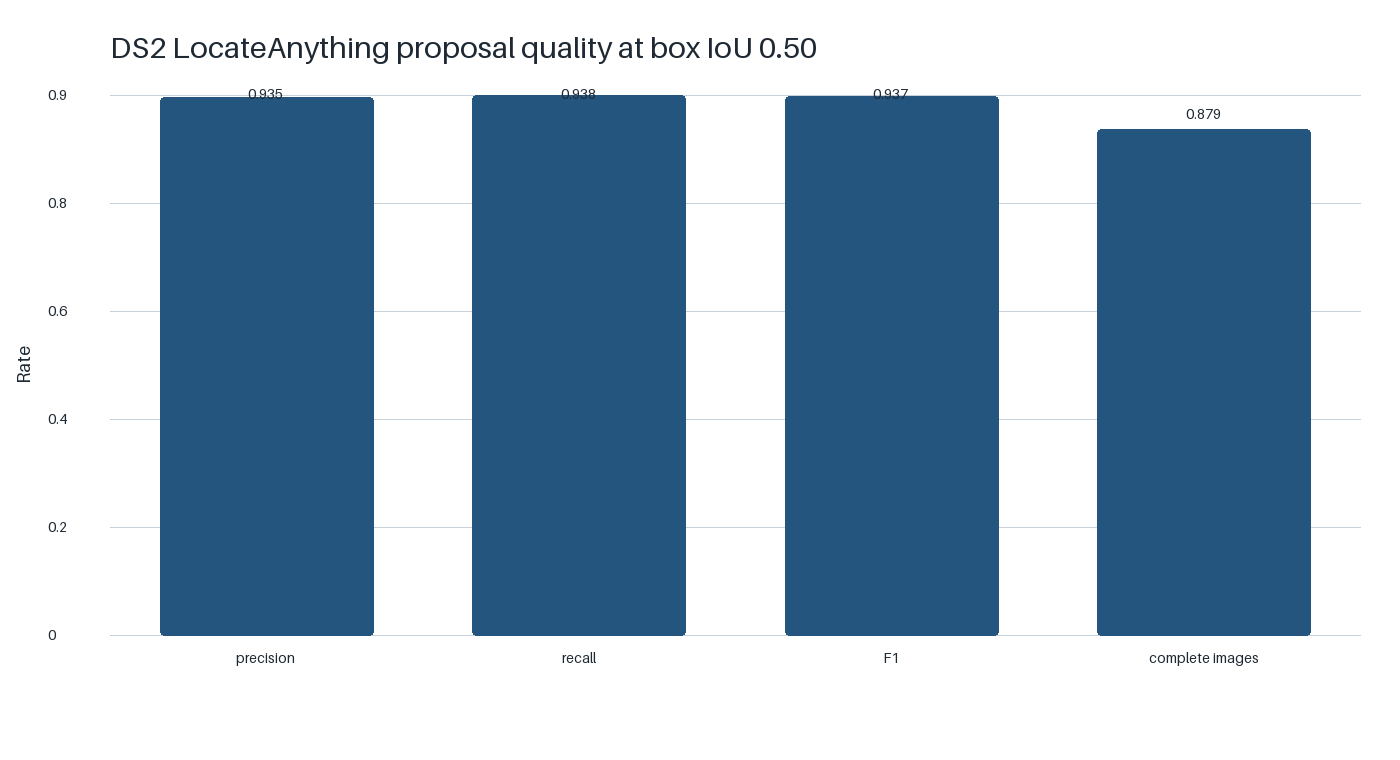

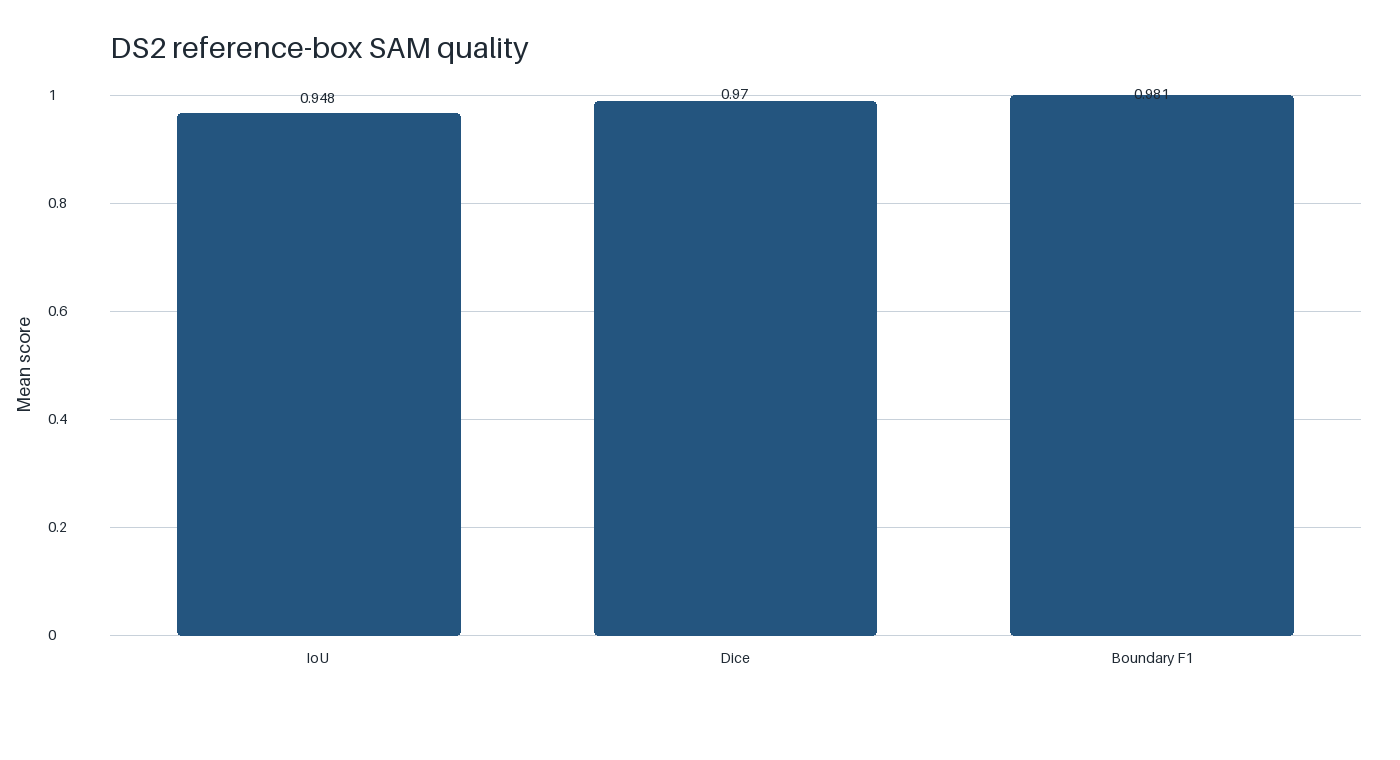

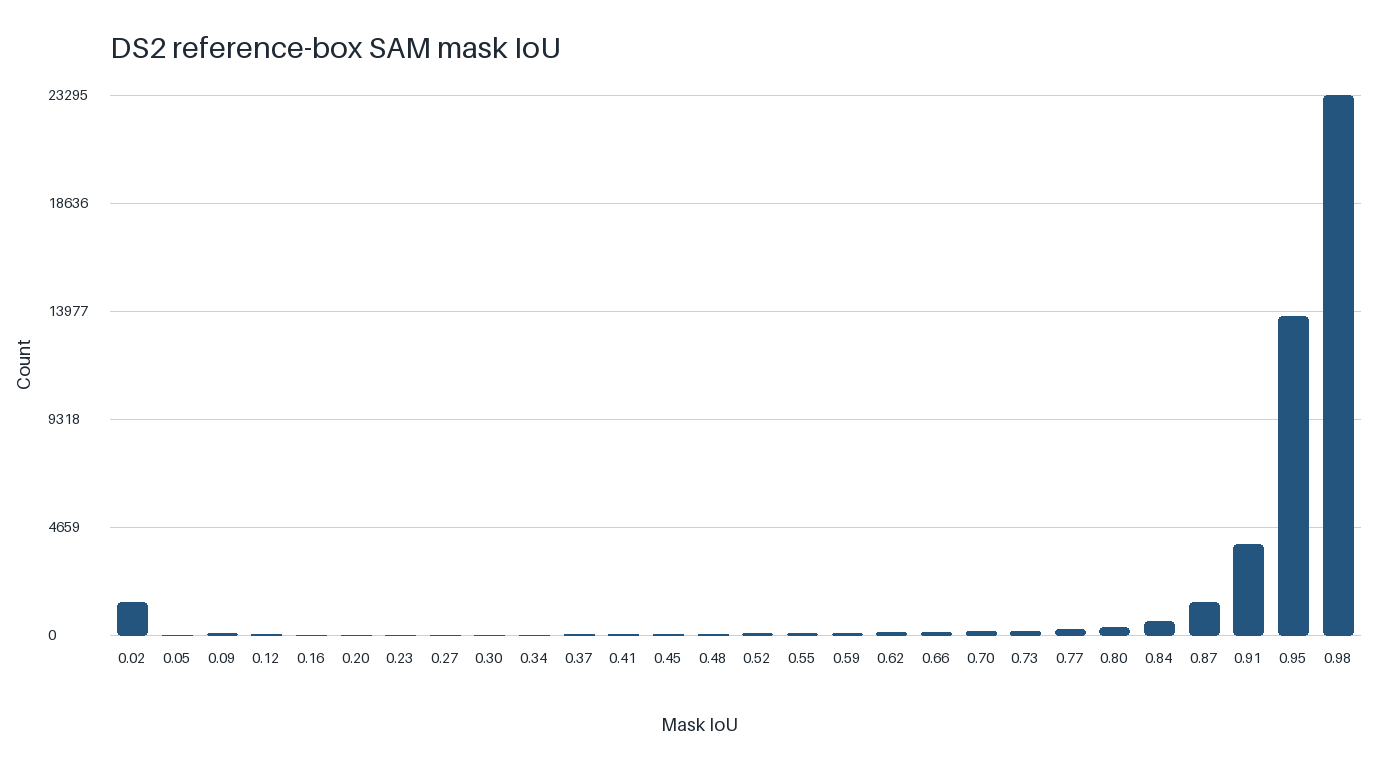

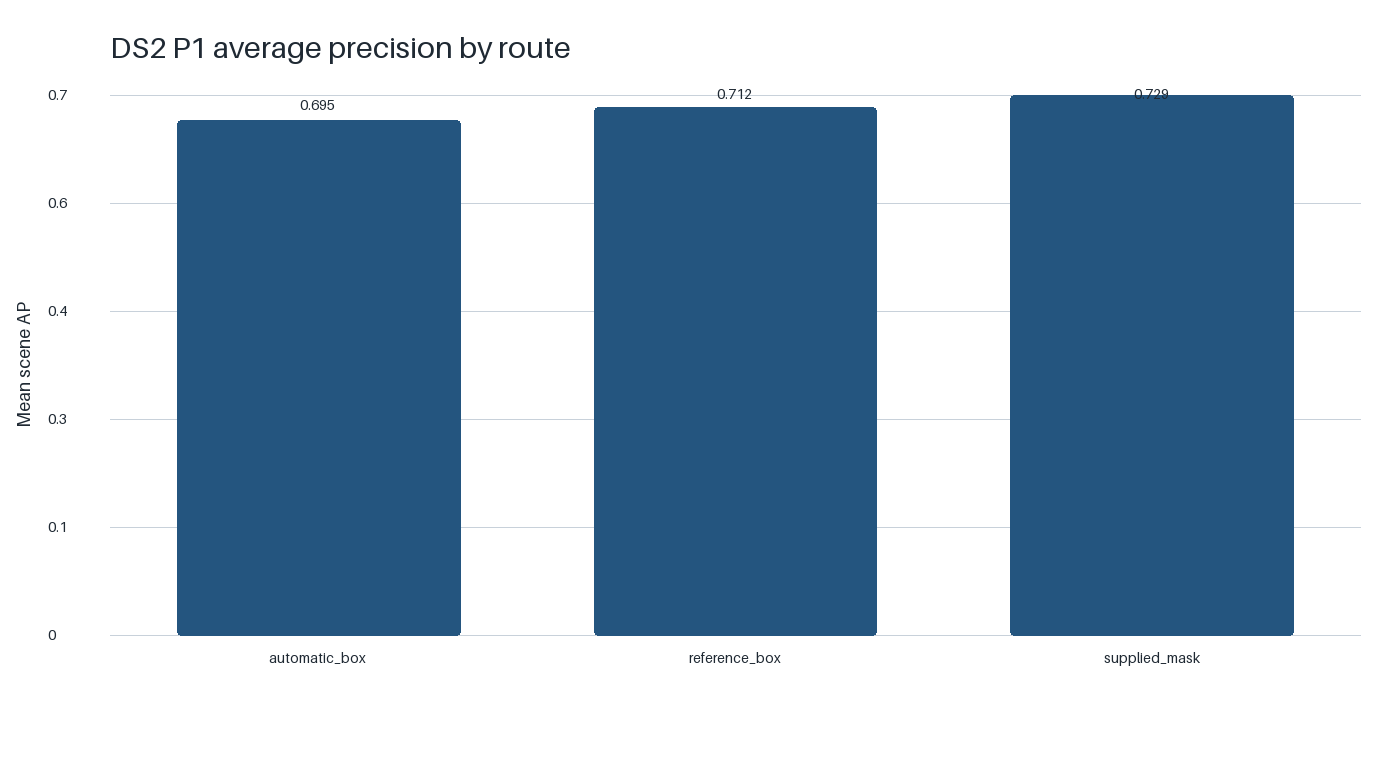

In [5]:
import pandas as pd

SAFE_ROOT = OUTPUT_ROOT / "safe"
display(pd.read_csv(SAFE_ROOT / "proposal_summary.csv"))
display(pd.read_csv(SAFE_ROOT / "mask_summary.csv"))
display(pd.read_csv(SAFE_ROOT / "unscoreable_summary.csv"))
display(pd.read_csv(SAFE_ROOT / "decision_gates.csv"))
display(pd.read_csv(SAFE_ROOT / "paired_intervals.csv"))
display(NotebookImage(filename=str(SAFE_ROOT / "locateanything_proposal_quality.png")))
display(NotebookImage(filename=str(SAFE_ROOT / "sam_mask_quality.png")))
display(NotebookImage(filename=str(SAFE_ROOT / "sam_mask_iou_distribution.png")))
display(NotebookImage(filename=str(SAFE_ROOT / "route_average_precision.png")))

## View-count and fusion results

,route,method,view_count,fusion_method,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set,rank_disagreement,confidence_margin
12,automatic_box,P1,1,mean_rank,300,0.463333,0.671452,0.651992,0.636667,0.350000,0.000000,0.351897
13,automatic_box,P1,1,visibility_weighted_rank,300,0.463333,0.671452,0.651992,0.636667,0.350000,0.000000,0.351897
16,automatic_box,P1,2,mean_rank,300,0.516667,0.697904,0.680342,0.646667,0.413333,0.160263,0.237909
17,automatic_box,P1,2,visibility_weighted_rank,300,0.513333,0.693737,0.676731,0.640000,0.406667,0.160263,0.248055
20,automatic_box,P1,3,mean_rank,300,0.463333,0.667499,0.653077,0.653333,0.383333,0.229898,0.207320
21,automatic_box,P1,3,visibility_weighted_rank,300,0.466667,0.670777,0.659493,0.666667,0.396667,0.229898,0.206818
22,automatic_box,P1,5,mean_rank,300,0.516667,0.705556,0.685164,0.673333,0.406667,0.266181,0.180805
23,automatic_box,P1,5,visibility_weighted_rank,300,0.506667,0.700612,0.684995,0.671667,0.413333,0.266181,0.181586
14,automatic_box,P1,10,mean_rank,300,0.540000,0.723033,0.702148,0.693333,0.426667,0.270822,0.169661
15,automatic_box,P1,10,visibility_weighted_rank,300,0.553333,0.727366,0.708981,0.690000,0.450000,0.270822,0.173184


,route,method,view_count,fusion_method,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set,rank_disagreement,confidence_margin
6,automatic_box,B0,20,mean_rank,300,0.476667,0.679383,0.658029,0.635000,0.356667,0.255102,0.161930
18,automatic_box,P1,20,mean_rank,300,0.526667,0.713550,0.695418,0.678333,0.413333,0.257014,0.165817
30,reference_box,B0,20,mean_rank,300,0.503333,0.702278,0.680667,0.671667,0.383333,0.335412,0.174736
42,reference_box,P1,20,mean_rank,300,0.560000,0.734111,0.712083,0.686667,0.440000,0.336694,0.185389
54,supplied_mask,B0,20,mean_rank,300,0.500000,0.699333,0.678333,0.676667,0.393333,0.332072,0.176819
66,supplied_mask,P1,20,mean_rank,300,0.580000,0.748833,0.728861,0.715000,0.466667,0.335356,0.192736


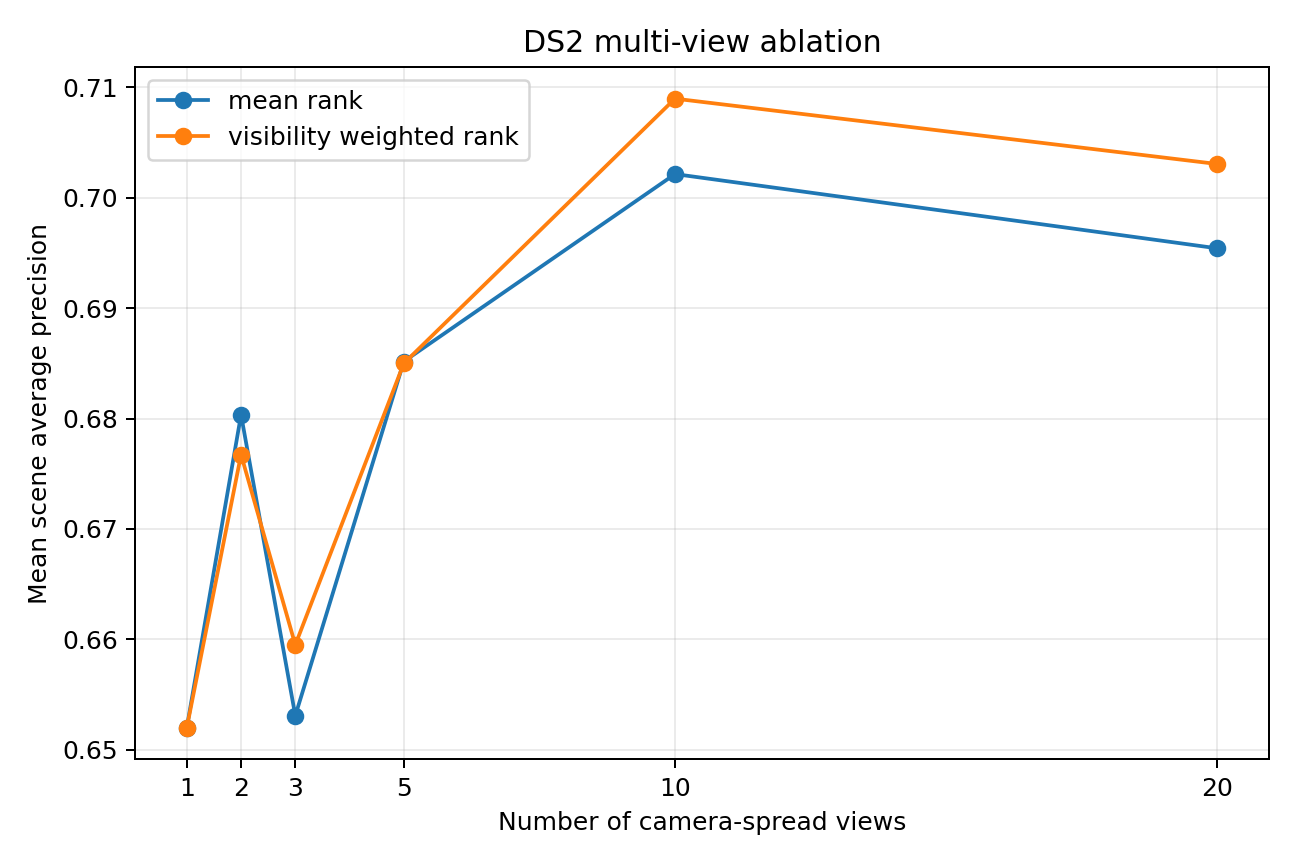

,route,method,view_count,fusion_method,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set,rank_disagreement,confidence_margin
0,automatic_box,P1,3,mean_rank,300,0.463333,0.667499,0.653077,0.653333,0.383333,0.229898,0.207320
1,automatic_box,P1,3,visibility_weighted_rank,300,0.466667,0.670777,0.659493,0.666667,0.396667,0.229898,0.206818


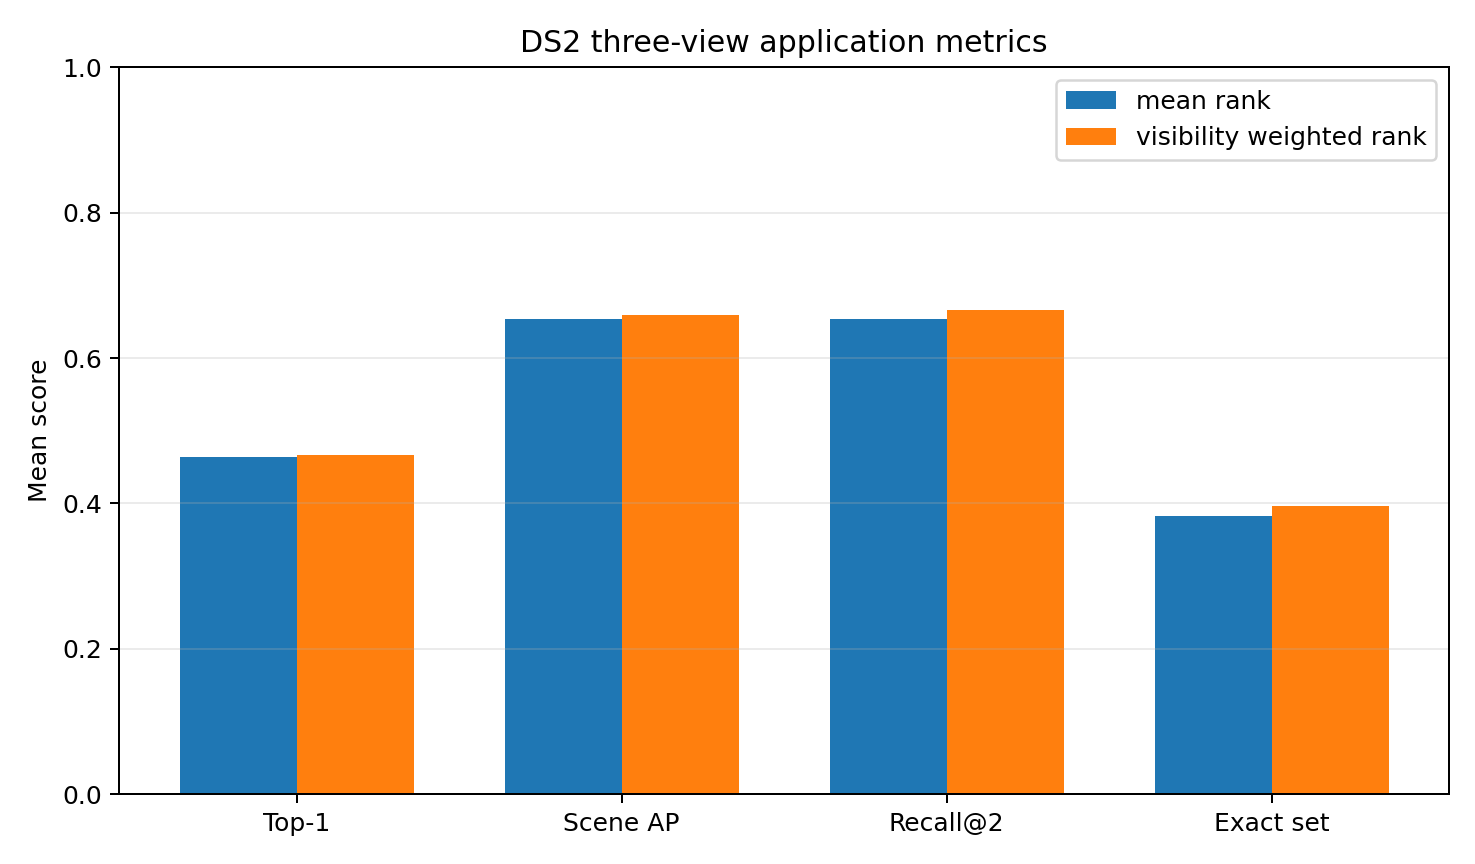

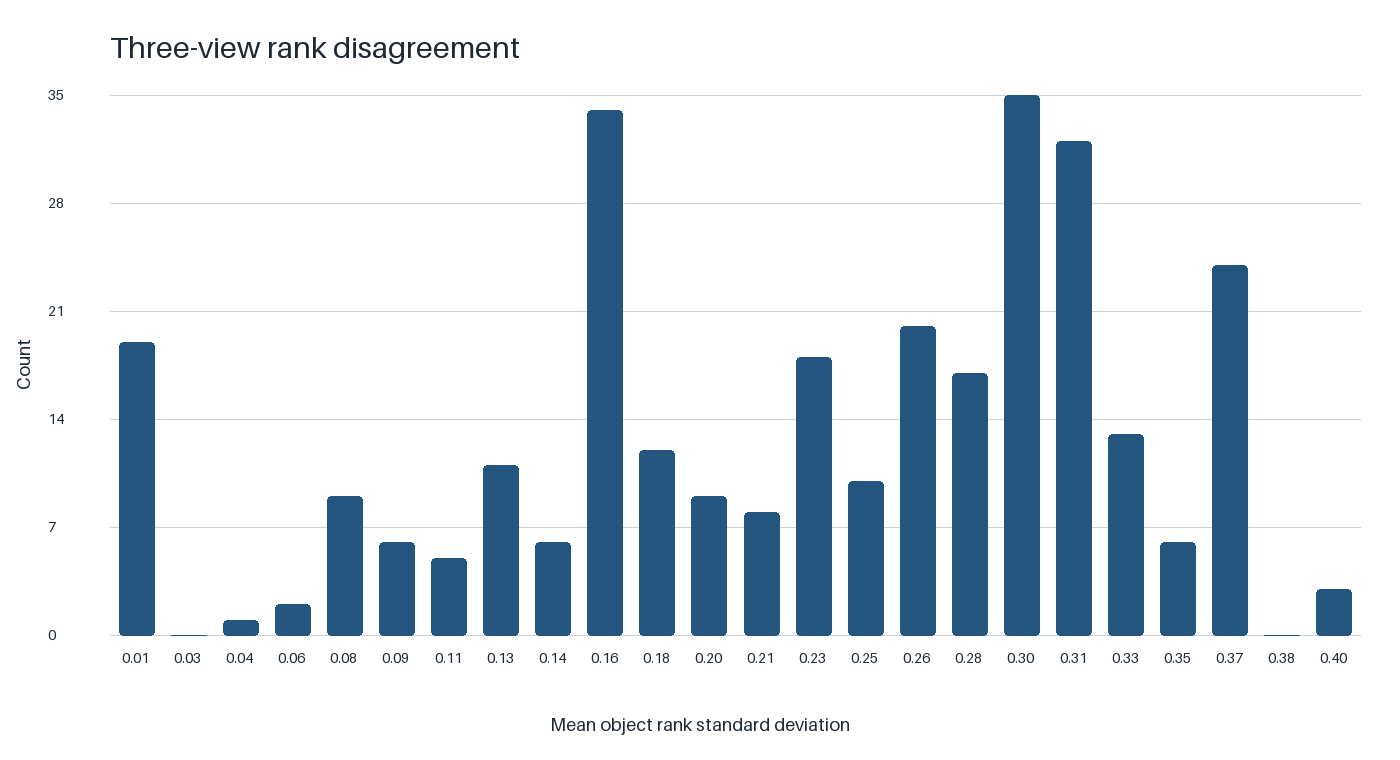

Fusion uses only scored ranks and applies scored-view support once. Detected support remains a separate coverage measure.


In [6]:
multiview = pd.read_csv(SAFE_ROOT / "multiview_summary.csv")
automatic_curve = multiview.query("route == 'automatic_box' and method == 'P1'")
display(automatic_curve.sort_values(["view_count", "fusion_method"]))
display(multiview.query("view_count == 20 and fusion_method == 'mean_rank'").sort_values(["route", "method"]))
display(NotebookImage(filename=str(SAFE_ROOT / "multiview_ablation.png")))
display(pd.read_csv(SAFE_ROOT / "primary_three_view_summary.csv"))
display(NotebookImage(filename=str(SAFE_ROOT / "primary_three_view_metrics.png")))
display(NotebookImage(filename=str(SAFE_ROOT / "rank_disagreement_distribution.png")))
print("Fusion uses only scored ranks and applies scored-view support once. Detected support remains a separate coverage measure.")

## Subgroups and real failure examples

In [7]:
subgroups = pd.read_csv(SAFE_ROOT / "subgroup_summary.csv")
display(subgroups.sort_values(["dimension", "average_precision"]).groupby("dimension").head(8))
display(pd.read_csv(SAFE_ROOT / "scene_type_summary.csv"))
display(NotebookImage(filename=str(SAFE_ROOT / "scene_type_metrics.png")))
display(NotebookImage(filename=str(SAFE_ROOT / "lowest_supported_subgroups.png")))
print("The private panel labels each example by route and score. Box and mask outlines show the evidence used for each prediction, and missed references are marked explicitly.")
display(NotebookImage(filename=str(OUTPUT_ROOT / "private/figures/three_view_success_and_failure.png")))

,dimension,value,fusion_method,scene_count,average_precision,top1,exact_set
128,anomaly_count,1,mean_rank,225,0.632326,0.413333,0.413333
129,anomaly_count,1,visibility_weighted_rank,225,0.640771,0.422222,0.422222
130,anomaly_count,2,mean_rank,75,0.715327,0.613333,0.293333
131,anomaly_count,2,visibility_weighted_rank,75,0.715661,0.600000,0.320000
85,anomaly_families,bump+frac,visibility_weighted_rank,1,0.325000,0.000000,0.000000
84,anomaly_families,bump+frac,mean_rank,1,0.366667,0.000000,0.000000
120,anomaly_families,tran,mean_rank,3,0.380952,0.000000,0.000000
121,anomaly_families,tran,visibility_weighted_rank,3,0.380952,0.000000,0.000000
103,anomaly_families,defr+miss,visibility_weighted_rank,1,0.500000,0.000000,0.000000
113,anomaly_families,frac+rota,visibility_weighted_rank,2,0.500000,0.000000,0.000000


,anomaly_count,fusion_method,scene_count,top1,average_precision,recall_at_2,exact_set
0,1,mean_rank,225,0.413333,0.632326,0.684444,0.413333
1,1,visibility_weighted_rank,225,0.422222,0.640771,0.702222,0.422222
2,2,mean_rank,75,0.613333,0.715327,0.560000,0.293333
3,2,visibility_weighted_rank,75,0.600000,0.715661,0.560000,0.320000


<IPython.core.display.Image object>

<IPython.core.display.Image object>

The private panel labels each example by route and score. Box and mask outlines show the evidence used for each prediction, and missed references are marked explicitly.


<IPython.core.display.Image object>

## Frozen configuration and confirmation status

In [8]:
decision = json.loads((SAFE_ROOT / "model_and_route_decision.json").read_text(encoding="utf-8"))
display(pd.DataFrame([decision]))
print(f"Encoder: {decision['encoder']}")
print(f"Scorer: {decision['scorer']}")
print(f"Application mask route: {decision['application_mask_route']}")
print(f"Primary views: {decision['primary_view_ids']}")
print(f"Fusion: {decision['fusion_method']}")
print(f"Decision status: {decision['status']}")

,accuracy_acceptance_gate_applied,application_mask_route,claim_boundary,ds2_used_for_tuning,encoder,fusion_method,primary_view_count,primary_view_ids,reference_diagnostic_route,schema_version,scientific_anchor_route,scorer,status
0,False,automatic_box,Development confirmation only. Calibration and...,False,dinov2_small,mean_rank,3,"[V00, V06, V13]",reference_box,1,supplied_mask,P1,confirmation_measured


Encoder: dinov2_small
Scorer: P1
Application mask route: automatic_box
Primary views: ['V00', 'V06', 'V13']
Fusion: mean_rank
Decision status: confirmation_measured


## Bounded ClearML finalisation

Only aggregate tables, figures, decisions, and hashes are uploaded. Per-scene scores, object IDs, labels, masks, RGB images, and failure panels remain in private Kaggle output.

In [9]:
if EXECUTION_ENVIRONMENT == "kaggle":
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_ROOT / "requirements/confirmation-tracking-lock.txt")], check=True, timeout=180)
    except Exception as error:
        print(f"ClearML dependency setup was unavailable: {type(error).__name__}")
tracking_receipt = run_clearml_finalizer(
    SAFE_ROOT,
    "ds2_confirmation_and_multiview",
    "ds2-confirmation-and-multiview",
    ["notebook-08c", "ds2", "multiview", "fusion", "kaggle"],
    OUTPUT_ROOT / "clearml_receipt.json",
)
display(tracking_receipt)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.3 MB/s eta 0:00:00


{'mode': 'disabled',
 'run_status': 'completed',
 'safe_manifest_sha256': 'cb67f1869cba05e56f5fd9cd0d4f89286916e7397432a48e9938dd9241fe599c',
 'schema_version': 1,
 'stage': 'ds2_confirmation_and_multiview_clearml_finalisation',
 'status': 'disabled',
 'task_id': None,
 'tracking_attempt_count': 0,
 'tracking_retry_count': 0,
 'tracking_transient_failure_count': 0}

## Build compact verified downloads

The repository archive contains aggregate tables, charts, decisions, and hashes. The review archive contains only the selected private success and failure panel. Per-scene scores, masks, RGB images, credentials, and extracted evaluator inputs are not included in the GitHub candidate.

In [10]:
BUNDLE_ROOT = (
    Path("/kaggle/working/notebook08c_bundles")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else OUTPUT_ROOT.parent / "notebook08c_bundles"
)
verification_path = BUNDLE_ROOT / "ds2-confirmation-and-multiview-verification.json"
if not verification_path.is_file():
    subprocess.run(
        [
            sys.executable,
            str(CODE_ROOT / "scripts/package_kaggle_stage_output.py"),
            "--stage-root", str(OUTPUT_ROOT),
            "--output-root", str(BUNDLE_ROOT),
            "--stage-name", "ds2-confirmation-and-multiview",
            "--review-path", "private/figures",
            "--review-path", "clearml_receipt.json",
        ],
        check=True,
        env=code_environment(),
    )
bundle_record = json.loads(verification_path.read_text(encoding="utf-8"))
display(pd.DataFrame(bundle_record["archives"]))
print(f"Verified downloads: {BUNDLE_ROOT}")

{"archives": [{"path": "ds2-confirmation-and-multiview-repository-evidence.zip", "sha256": "3b0a38cbdcd4c0d63a00a48ad17d89f0e7fd86a75d2d1311e11c6e0b725b2260", "size_bytes": 328996, "source_file_count": 22}, {"path": "ds2-confirmation-and-multiview-review-evidence.zip", "sha256": "e7e99d5447fb915073fa4ce953e9ebe2b32f3e7b63a5361bc7185de11ccc7ea5", "size_bytes": 705887, "source_file_count": 2}], "downstream_file_count": 0, "review_file_count": 2, "safe_file_count": 22, "safe_manifest_sha256": "cb67f1869cba05e56f5fd9cd0d4f89286916e7397432a48e9938dd9241fe599c", "schema_version": 1, "stage": "ds2-confirmation-and-multiview", "status": "completed"}


,path,sha256,size_bytes,source_file_count
0,ds2-confirmation-and-multiview-repository-evid...,3b0a38cbdcd4c0d63a00a48ad17d89f0e7fd86a75d2d13...,328996,22
1,ds2-confirmation-and-multiview-review-evidence...,e7e99d5447fb915073fa4ce953e9ebe2b32f3e7b63a536...,705887,2


Verified downloads: /kaggle/working/notebook08c_bundles


## Next stage

Record the measured automatic and assisted routes separately. DS2 measures the predeclared SAM 2.1 Hiera-large, DINOv2-small, B0, P1, three-view, and mean-rank configuration without tuning it. Keep that configuration unchanged for the next development scale run. The automatic route remains experimental until a label-free cross-view association method replaces the evaluator-only box matching used in this notebook.

The next two weeks should scale the frozen method to the 1,000-scene development role, implement label-free cross-view association and the assisted review flow, then use the 600-scene calibration role only to set a review threshold. Internal-lock and official evaluation remain unopened until those choices are frozen.